# Почему доставка опаздывает



In [1]:
import sys
import math
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
RANDOM_STATE = 42
DATA = Path('data')
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
print('Python',sys.version.split()[0], 'pandas',pd.__version__, 'matplotlib',matplotlib.__version__)
def say(s):
    display(Markdown('**Вывод.** '+s))
def save(fig,name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name+'.png'),dpi=130,bbox_inches='tight')
    plt.show()


Python 3.12.14 pandas 3.0.6 matplotlib 3.10.9


## 1. Цель
Руководителю доставки нужны масштаб нарушений обещания и проверяемое решение. Метрика — доля доставок позже обещанного среди доставок с пригодным временем. Критерий пилота: не менее 80% выбранной подгруппы укладываются в новый срок.

**Главное.** В пригодных данных опоздали 441/1841 доставки (24.0%); для полной выгрузки крайние сценарии дают 23.5–25.4%. Самая проблемная группа — пешие: 298/403 (73.9%). При обещании 30 минут разрыв сохраняется; на исходных маршрутах п80 этой подгруппы равен 40 минутам. Предлагаю проверить срок 40 минут небольшим контролируемым пилотом и следить за отказами от заказа.

## 2. Данные
Одна строка — одна доставка сети за сентябрь–ноябрь 2026. Известны обещание, факт, расстояние, тип курьера, погода и добровольная оценка. Источник — публичная учебная выгрузка. Статус исключённых доставок неизвестен.

In [2]:
raw=pd.read_csv(DATA/'deliveries.csv',parse_dates=['created'])
print(raw.shape, raw.created.min(),raw.created.max())
print(raw.isna().sum())
print('Полные дубли:',raw.duplicated().sum())
display(raw.head())
say(f'В выгрузке {len(raw)} строк; время отсутствует у {raw.actual_min.isna().sum()}. Пропуски rating не заполняю — это добровольный ответ гостя.')

(1877, 11) 2026-09-01 11:43:00 2026-11-30 21:32:00
delivery_id       0
created           0
shop_id           0
courier           0
distance_km       0
weather           0
items             0
amount            0
promised_min      0
actual_min       25
rating          822
dtype: int64
Полные дубли: 0


,delivery_id,created,shop_id,courier,distance_km,weather,items,amount,promised_min,actual_min,rating
0,DL-00001,2026-09-01 11:43:00,PRM-2,пеший,1.1,ясно,6,1527,30,31.0,NaN
1,DL-00002,2026-09-01 13:06:00,PRM-1,авто,4.2,облачно,5,1172,45,37.0,5.0
2,DL-00003,2026-09-01 13:12:00,PRM-1,вело,4.6,ясно,2,522,45,44.0,NaN
3,DL-00004,2026-09-01 14:45:00,PRM-1,авто,2.4,ясно,5,1242,45,24.0,NaN
4,DL-00005,2026-09-01 16:04:00,UFA-1,авто,9.4,ясно,2,460,60,33.0,5.0


**Вывод.** В выгрузке 1877 строк; время отсутствует у 25. Пропуски rating не заполняю — это добровольный ответ гостя.

**Вывод по данным.** Период осени наблюдается целиком, но неделя на каждом краю неполная. Анализ оценок относится только к ответившим гостям.

## 3. Предобработка
Правдоподобный интервал фактического времени — 1–299 минут: крайние значения после 735 минут отделены от реальных доставок большим разрывом. Изъятие этих строк не превращает их в своевременные доставки.

In [3]:
ok=raw[raw.actual_min.between(1,299)].copy()
ok['late']=ok.actual_min>ok.promised_min
ok['delay']=ok.actual_min-ok.promised_min
ok['hour']=ok.created.dt.hour
log={'всего':len(raw),'без времени':int(raw.actual_min.isna().sum()),'невозможное время':int((raw.actual_min.notna()&~raw.actual_min.between(1,299)).sum()),'осталось':len(ok)}
display(pd.Series(log,name='доставок').to_frame())
missing=raw[~raw.index.isin(ok.index)].groupby('courier').size()
limits=pd.DataFrame({'late':ok.groupby('courier').late.sum(),'all':raw.groupby('courier').size(),'excluded':missing}).fillna(0)
limits['lower_pct']=limits.late/limits['all']*100
limits['upper_pct']=(limits.late+limits.excluded)/limits['all']*100
display(limits.round(1))
say(f'Осталось {len(ok)}/{len(raw)} строк. Общая доля лежит между {ok.late.sum()/len(raw):.1%} и {(ok.late.sum()+len(raw)-len(ok))/len(raw):.1%} в крайних сценариях; это не доверительный интервал.')

,доставок
всего,1877
без времени,25
невозможное время,11
осталось,1841


,late,all,excluded,lower_pct,upper_pct
courier,,,,,
авто,30,581,15,5.2,7.7
вело,113,888,16,12.7,14.5
пеший,298,408,5,73.0,74.3


**Вывод.** Осталось 1841/1877 строк. Общая доля лежит между 23.5% и 25.4% в крайних сценариях; это не доверительный интервал.

**Вывод по предобработке.** Исключены 25 пропусков и 11 невозможных значений. Концентрацию потерь по курьерам показал отдельно: малое число потерь в целом не гарантирует малый эффект в группе.

## 4. Анализ
Проверяю масштаб, признаки, обещание внутри курьеров, состав KZN-2, снег и недели, оценки и две собственные группы.

### 4.1. Масштаб
Длительность описываю медианой и квантилями, а нарушение обещания — долей late.

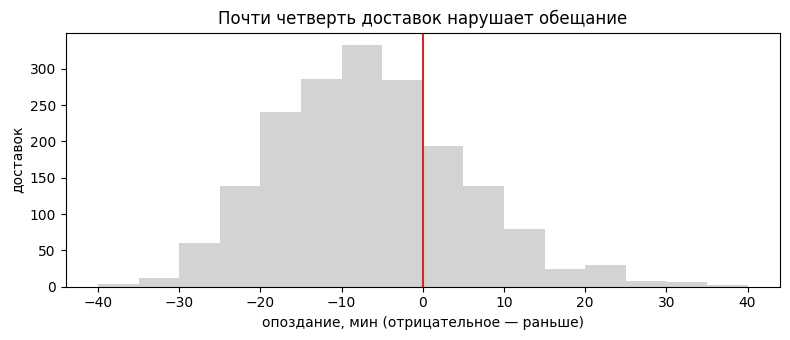

**Вывод.** Опоздали 441/1841 (24.0%). Среди опоздавших медиана задержки 7.0 мин, п90 20.0 мин. Окно графика −40…40; вне него 2 доставок.

In [4]:
late_pct=round(ok.late.mean()*100,1)
late_median=ok.loc[ok.late,'delay'].median()
p90_late=ok.loc[ok.late,'delay'].quantile(.9)
fig,ax=plt.subplots(figsize=(8,3.5))
ax.hist(ok.delay,bins=16,range=(-40,40),color='lightgray')
ax.axvline(0,color='tab:red')
ax.set(title='Почти четверть доставок нарушает обещание',xlabel='опоздание, мин (отрицательное — раньше)',ylabel='доставок')
save(fig,'scale')
say(f'Опоздали {ok.late.sum()}/{len(ok)} ({late_pct}%). Среди опоздавших медиана задержки {late_median:.1f} мин, п90 {p90_late:.1f} мин. Окно графика −40…40; вне него {((ok.delay < -40)|(ok.delay>40)).sum()} доставок.')

**Вывод по масштабу.** Нарушение обещания встречается регулярно. Одна средняя длительность скрыла бы и своевременные доставки, и хвост задержек.

### 4.2. Признаки
Размах доли между группами — ориентир порядка исследования, а не причинная важность.

courier    68.6
items      22.3
hour       20.9
weather    15.0
shop_id    13.1
dtype: float64

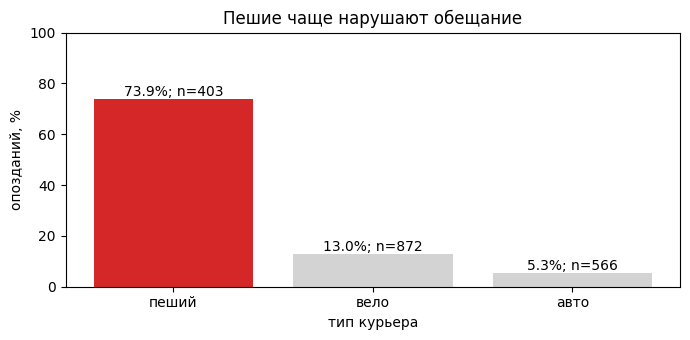

**Вывод.** Наибольший размах у courier: 68.6 п.п. Число групп и их размеры различаются; это связь, не оценка причинного эффекта.

In [5]:
r={}
for col in ['courier','weather','shop_id','items','hour']:
    g=ok.groupby(col).late.agg(['mean','size'])
    s=g[g['size']>=50]['mean']
    r[col]=round((s.max()-s.min())*100,1)
ranking=pd.Series(r).sort_values(ascending=False)
top_factor=ranking.index[0]
display(ranking)
g=ok.groupby(top_factor).late.agg(n='size',share='mean').sort_values('share',ascending=False)
fig,ax=plt.subplots(figsize=(7,3.5))
bars=ax.bar(g.index,g.share*100,color=['tab:red']+['lightgray']*(len(g)-1))
ax.bar_label(bars,labels=[f'{s:.1%}; n={n}' for s,n in zip(g.share,g.n)])
ax.set(title='Пешие чаще нарушают обещание',xlabel='тип курьера',ylabel='опозданий, %',ylim=(0,100))
save(fig,'factors')
say(f'Наибольший размах у {top_factor}: {ranking.iloc[0]} п.п. Число групп и их размеры различаются; это связь, не оценка причинного эффекта.')

**Вывод по признакам.** Начинаю с курьера и проверяю, не отражает ли он только короткое обещание.

### 4.3. Обещание и выбранная группа
Группу выбираю вычислением, при равенстве — первое название по алфавиту.

courier,авто,вело,пеший
promised_min,,,
30,17.6,24.4,69.7
45,1.4,7.8,89.5
60,4.3,21.4,NaN


courier,авто,вело,пеший
promised_min,,,
30,102.0,238.0,317.0
45,278.0,592.0,86.0
60,186.0,42.0,NaN


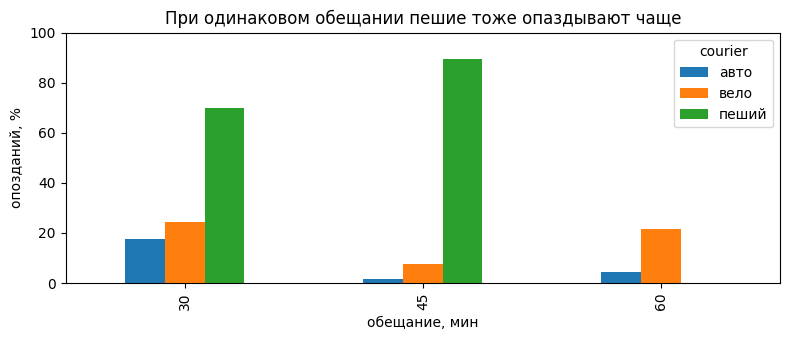

**Вывод.** Выбраны пеший. При 30 мин: 221/317 опозданий. П80 40.0 мин; кандидат 40 мин, уложились бы 258/317 (81.4%). При 45 мин медианы расстояния 3.0 км и времени 59.5 мин: маршруты иные. Пересчёт срока не ускоряет курьера.

In [6]:
chosen=ok.groupby('courier').late.mean().sort_index().idxmax()
pv=ok.pivot_table(index='promised_min',columns='courier',values='late',aggfunc='mean')*100
counts=ok.pivot_table(index='promised_min',columns='courier',values='late',aggfunc='size')
display(pv.round(1));display(counts)
s=ok[(ok.courier==chosen)&(ok.promised_min==30)]
walk_p80=s.actual_min.quantile(.8)
fair_promise=math.ceil(walk_p80/5)*5
s45=ok[(ok.courier==chosen)&(ok.promised_min==45)]
walk45_km=s45.distance_km.median();walk45_min=s45.actual_min.median()
fig,ax=plt.subplots(figsize=(8,3.5))
pv.plot(kind='bar',ax=ax)
ax.set(title='При одинаковом обещании пешие тоже опаздывают чаще',xlabel='обещание, мин',ylabel='опозданий, %',ylim=(0,100))
save(fig,'promise')
say(f'Выбраны {chosen}. При 30 мин: {s.late.sum()}/{len(s)} опозданий. П80 {walk_p80} мин; кандидат {fair_promise} мин, уложились бы {(s.actual_min<=fair_promise).sum()}/{len(s)} ({(s.actual_min<=fair_promise).mean():.1%}). При 45 мин медианы расстояния {walk45_km:.1f} км и времени {walk45_min:.1f} мин: маршруты иные. Пересчёт срока не ускоряет курьера.')

**Вывод по обещанию.** Пилот срока 40 минут имеет опору в исходных маршрутах. Если при сопоставимых маршрутах своевременность не достигает 80% или отказы растут настолько, что маржа падает, рекомендация не поддерживается.

### 4.4. Кофейня KZN-2
Проверяю разницу внутри курьера; расстояние остаётся возможным смешивающим фактором.

In [7]:
ok['kzn2']=ok.shop_id=='KZN-2'
a=ok.groupby(['courier','kzn2']).actual_min.median().unstack()
b=ok.groupby(['courier','kzn2']).distance_km.median().unstack()
kzn2_gap=(a[True]-a[False]).to_dict();same_distance=(b[True]-b[False]).round(1).to_dict()
display(pd.DataFrame({'разница времени, мин':kzn2_gap,'разница расстояния, км':same_distance}))
display(ok.groupby(['courier','kzn2']).size())
say(f'Разницы медианного времени KZN-2 минус остальные: {kzn2_gap}. Разницы расстояния {same_distance}; сравнение внутри курьеров ещё не уравнивает погоду, часы и маршруты.')

,"разница времени, мин","разница расстояния, км"
авто,6.0,0.1
вело,4.0,-0.1
пеший,4.5,0.0


courier  kzn2 
авто     False    483
         True      83
вело     False    743
         True     129
пеший    False    343
         True      60
dtype: int64

**Вывод.** Разницы медианного времени KZN-2 минус остальные: {'авто': 6.0, 'вело': 4.0, 'пеший': 4.5}. Разницы расстояния {'авто': 0.1, 'вело': -0.1, 'пеший': 0.0}; сравнение внутри курьеров ещё не уравнивает погоду, часы и маршруты.

**Вывод по KZN-2.** Сравнение условий уточняет картину; причинную вину управляющего по общей доле установить нельзя.

### 4.5. Снег и время
Исключаю крайние неполные недели. Разница долей и отношение — разные вопросы.

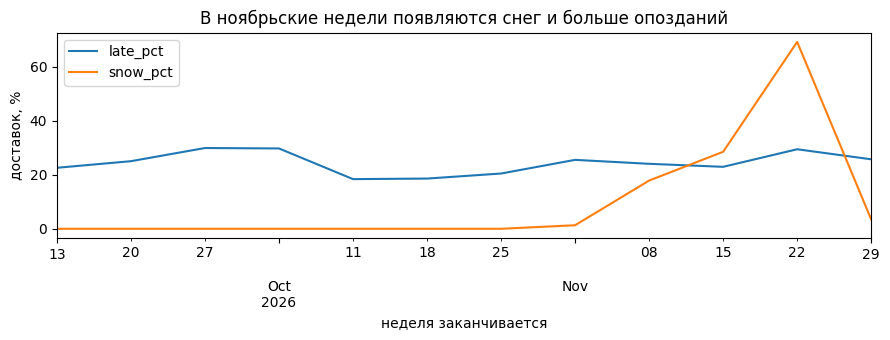

sum  size      mean
courier snow                      
авто    False   25   491  0.050916
        True     5    75  0.066667
вело    False   94   816  0.115196
        True    19    56  0.339286
пеший   False  265   368  0.720109
        True    33    35  0.942857

**Вывод.** Недельная корреляция долей 0.34; полных недель 12. Снег был только в ноябре, поэтому и другие ноябрьские изменения могли объяснять связь.

In [8]:
ok['snow']=ok.weather=='снег'
weeks=ok.set_index('created').resample('W')[['late','snow']].mean().iloc[1:-1]*100
weeks.columns=['late_pct','snow_pct'];r_weeks=round(weeks.late_pct.corr(weeks.snow_pct),2)
fig,ax=plt.subplots(figsize=(9,3.5));weeks.plot(ax=ax)
ax.set(title='В ноябрьские недели появляются снег и больше опозданий',xlabel='неделя заканчивается',ylabel='доставок, %')
save(fig,'weeks')
display(ok.groupby(['courier','snow']).late.agg(['sum','size','mean']))
say(f'Недельная корреляция долей {r_weeks}; полных недель {len(weeks)}. Снег был только в ноябре, поэтому и другие ноябрьские изменения могли объяснять связь.')

**Вывод по снегу.** Сравнение внутри курьеров не снимает календарное смешение. Нужны сопоставимые снеговые и бесснежные маршруты, даты и часы.

### 4.6. Оценки
Оценки добровольные. Близость долей отвечающих не доказывает одинаковый отбор довольных и недовольных.

,rating,n
delay,,
"(-60, -10]",4.78,443
"(-10, 0]",4.76,335
"(0, 10]",4.33,181
"(10, 20]",3.31,48
"(20, 60]",1.89,27


late
False    0.555714
True     0.580499
Name: rating, dtype: float64

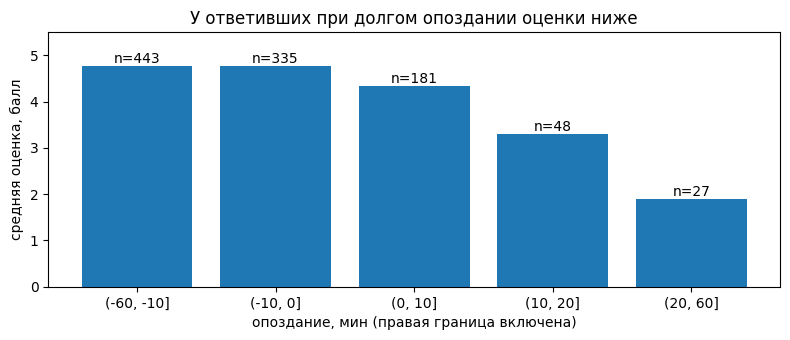

**Вывод.** Вовремя средняя 4.77; задержка >10 мин — 2.8, оценок 75, доля 3 и ниже 70.7%. Это связь среди ответивших, не доказательство причинности.

In [9]:
rating_on_time=round(ok.loc[~ok.late,'rating'].mean(),2)
s=ok.loc[ok.delay>10,'rating'].dropna()
rating_late10=round(s.mean(),2);low_share_late10=round((s<=3).mean()*100,1)
t=ok.groupby(pd.cut(ok.delay,[-60,-10,0,10,20,60]),observed=False).rating.agg(rating='mean',n='count')
display(t.round(2));display(ok.groupby('late').rating.apply(lambda x:x.notna().mean()))
fig,ax=plt.subplots(figsize=(8,3.5));bars=ax.bar(t.index.astype(str),t.rating)
ax.bar_label(bars,labels=[f'n={n}' for n in t.n]);ax.set(title='У ответивших при долгом опоздании оценки ниже',xlabel='опоздание, мин (правая граница включена)',ylabel='средняя оценка, балл',ylim=(0,5.5))
save(fig,'ratings')
say(f'Вовремя средняя {rating_on_time}; задержка >10 мин — {rating_late10}, оценок {len(s)}, доля 3 и ниже {low_share_late10}%. Это связь среди ответивших, не доказательство причинности.')

**Вывод по оценкам.** Предлагаю дополнительную метрику delay>10, сохраняя долю любых нарушений как контроль соблюдения обещания.

### 4.7. Собственные закономерности
Выбрал размер заказа и короткое расстояние; второе не трактую как эффект расстояния без состава.

**Вывод.** items >= 5: 86/225 (38.2%) против 355/1616 (22.0%). Возможны различия обещаний, курьеров и маршрутов.

sum  size      mean
courier inside                     
авто    False    21   492  0.042683
        True      9    74  0.121622
вело    False    88   777  0.113256
        True     25    95  0.263158
пеший   False   246   347  0.708934
        True     52    56  0.928571

**Вывод.** distance_km <= 2: 297/681 (43.6%) против 144/1160 (12.4%). Возможны различия обещаний, курьеров и маршрутов.

sum  size      mean
courier inside                     
авто    False    12   460  0.026087
        True     18   106  0.169811
вело    False    55   615  0.089431
        True     58   257  0.225681
пеший   False    77    85  0.905882
        True    221   318  0.694969

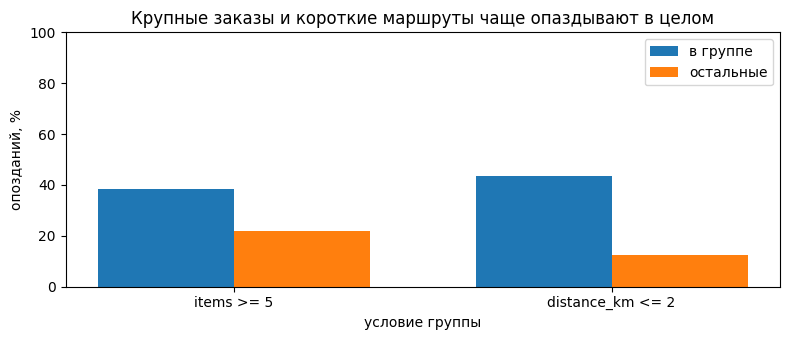

In [10]:
findings=[]
for condition in ['items >= 5','distance_km <= 2']:
    g=ok.query(condition);other=ok.drop(g.index)
    a=round(g.late.mean()*100,1);b=round(other.late.mean()*100,1)
    conclusion=f'{condition}: {g.late.sum()}/{len(g)} ({a}%) против {other.late.sum()}/{len(other)} ({b}%). Возможны различия обещаний, курьеров и маршрутов.'
    findings.append({'группа':condition,'n':len(g),'late_pct':a,'остальные_pct':b,'вывод':conclusion})
    say(conclusion)
    display(ok.assign(inside=ok.index.isin(g.index)).groupby(['courier','inside']).late.agg(['sum','size','mean']))
fig,ax=plt.subplots(figsize=(8,3.5))
x=np.arange(2)
ax.bar(x-.18,[f['late_pct'] for f in findings],width=.36,label='в группе')
ax.bar(x+.18,[f['остальные_pct'] for f in findings],width=.36,label='остальные')
ax.set_xticks(x);ax.set_xticklabels([f['группа'] for f in findings]);ax.legend()
ax.set(title='Крупные заказы и короткие маршруты чаще опаздывают в целом',xlabel='условие группы',ylabel='опозданий, %',ylim=(0,100))
save(fig,'own')

**Вывод по собственным находкам.** У items>=5 рост доли виден внутри всех типов курьера, но причинную роль размера это не доказывает. Для distance<=2 направление у пеших обратное общему: смесь курьеров и обещаний мешает назначить одно действие по общему сравнению.

### 4.8. Пересчитываемый отчёт
Функция принимает сырые данные; отсутствие пеших с обещанием 30 минут возвращает None, пустой пригодный период — пустые показатели.

In [11]:
def delivery_report(raw):
    ok=raw[raw.actual_min.between(1,299)].copy()
    if ok.empty:
        return dict(late_pct=None,worst_courier=None,worst_shop=None,peak_hours=[],fair_promise=None)
    ok["late"]=ok.actual_min>ok.promised_min
    ok["hour"]=ok.created.dt.hour
    g=ok.groupby("hour").late.agg(["mean","size"])
    s=ok[(ok.courier=="пеший")&(ok.promised_min==30)].actual_min
    promise=None if s.empty else math.ceil(s.quantile(.8)/5)*5
    return dict(late_pct=round(ok.late.mean()*100,1),worst_courier=ok.groupby("courier").late.mean().sort_index().idxmax(),worst_shop=ok.groupby("shop_id").late.mean().sort_index().idxmax(),peak_hours=g[(g["size"]>=50)&(g["mean"]>.25)].index.tolist(),fair_promise=promise)
raw=pd.read_csv(DATA/"deliveries.csv",parse_dates=["created"])
delivery_report(raw)

print(delivery_report(raw))
print(delivery_report(raw[raw.created.dt.month==11]))
print(delivery_report(raw.iloc[0:0]))


{'late_pct': np.float64(24.0), 'worst_courier': 'пеший', 'worst_shop': 'KZN-2', 'peak_hours': [12, 13, 18, 19], 'fair_promise': 40}
{'late_pct': np.float64(25.8), 'worst_courier': 'пеший', 'worst_shop': 'KZN-2', 'peak_hours': [12, 13, 18, 19], 'fair_promise': 45}
{'late_pct': None, 'worst_courier': None, 'worst_shop': None, 'peak_hours': [], 'fair_promise': None}


**Вывод по функции.** Отчёт воспроизводим для другого периода; fair_promise в этой функции следует публичному контракту про пеших, а выбор целевой группы пилота в анализе сделан вычислением.

## 5. Выводы и рекомендации
1. Нарушения обещания — 441/1841 (24.0%); неизвестные статусы дают диапазон всей выгрузки 23.5–25.4%.
2. Для пеших с обещанием 30 минут проверить 40 минут в пилоте с контролем: целевой порог своевременности 80%, дополнительно конверсия и маржа. Это мера честности обещания, а не ускорения.
3. Крупные заказы и короткие маршруты различаются с остальными; первая связь держится внутри типов курьера, вторая неоднородна. Проверить сборку крупных заказов отдельным пилотом.
4. Снег связан с опозданиями, но совпадает с ноябрём. Оценки добровольные; выводы о причинах ограничены.
5. Для решений нужны этапы сборки/ожидания/поездки, нагрузка, маршруты, конверсия и экономика. При отсутствии эффекта в контролируемом пилоте или падении маржи предложение пересмотреть.